# 01 · The inventory, the label and the survey structure
The ICIMOD (2025) community inventory of 5,689 water sources in seven municipalities of Kavrepalanchok
(doi:10.26066/RDS.1974131, CC BY 4.0), cleaned by `src/data_cleaning.py` and assembled with the versioned
covariate extractions by `src/assemble_master.py`. We took no part in the data collection; everything
here is a secondary analysis of the public release.

**The label.** `source_condition` (active / dried) is the condition recorded by the community resource
person at an undated visit between October 2023 and June 2024. The release contains no operational
definition of "dried", no discharge for dried sources, no visit date and no enumerator identifier.
Ponds and sources recorded as seasonal are treated as sensitivity cases throughout (notebook 10).

Running this notebook reproduces the boundary audit (`boundary_agreement.csv`) and the raw-field
skip-logic audit (`x0_raw_field_audit*.csv`).

In [1]:
import logging, os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s", stream=sys.stdout, force=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

M = ROOT / "results/metrics"
F = ROOT / "results/figures"

def table(name, **kw):
    return pd.read_csv(M / name, **kw).round(4)

def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
from src.dataset import load_master

df = load_master()
ward = df.municipality.astype(str) + "_" + df.ward.astype(str)
print(f"{len(df):,} sources | {df.municipality.nunique()} municipalities | {ward.nunique()} wards | "
      f"{df.target_dried.mean():.1%} recorded as dried")
pd.crosstab(df.source_type, df.source_condition, margins=True)

5,689 sources | 7 municipalities | 75 wards | 26.7% recorded as dried


source_condition,active,dried,All
source_type,,,
pond,264,257,521
spring,3904,1264,5168
All,4168,1521,5689


## Recorded drying by source type, seasonality and municipality

In [3]:
df.groupby(["source_type", "seasonality"]).target_dried.agg(n="size", dried_share="mean").round(3)

n  dried_share
source_type seasonality                   
pond        perennial     282        0.351
            seasonal      239        0.661
spring      perennial    4477        0.187
            seasonal      691        0.621

In [4]:
df.groupby("municipality").agg(sources=("id", "size"), wards=("ward", "nunique"),
                               dried_share=("target_dried", "mean")).sort_values("dried_share").round(3)

,sources,wards,dried_share
municipality,,,
Panauti,880,12,0.094
Bethanchownk,385,6,0.192
Namobuudha,478,11,0.201
Roshi RM,969,12,0.218
Dhulikhel,1174,12,0.288
Temal,736,9,0.398
Panchkhal,1067,13,0.399


## Wards: the units in which the survey was organised

count     75.0
mean      75.9
std       31.2
min       16.0
25%       53.5
50%       75.0
75%       95.5
max      164.0
Name: count, dtype: float64

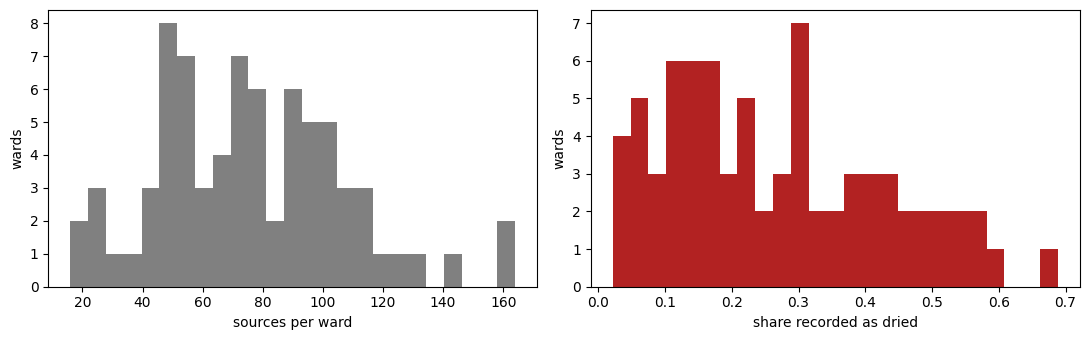

In [5]:
size = ward.value_counts()
rate = df.groupby(ward).target_dried.mean()
_f, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(size, bins=25, color="grey")
axes[0].set_xlabel("sources per ward"); axes[0].set_ylabel("wards")
axes[1].hist(rate, bins=25, color="firebrick")
axes[1].set_xlabel("share recorded as dried"); axes[1].set_ylabel("wards")
plt.tight_layout()
size.describe().round(1)

## Boundary audit
Recorded palika and ward identifiers are survey assignments. How many sources lie inside the official
polygon of their recorded palika?

In [6]:
from src.boundaries import run as audit_boundaries
audit_boundaries()
table("boundary_agreement.csv")

2026-11-10 15:53:35,520 [INFO] 
        palika  n_sources  inside_recorded_palika  n_outside  in_other_surveyed_palika  in_non_surveyed_kavre_palika  outside_district  median_dist_outside_m  share_outside_within_500m
0  Bethanchowk        385                   0.927         28                        13                             0                15                 98.721                      0.964
1    Dhulikhel       1174                   0.894        124                        35                            88                 1                159.197                      0.879
2   Namobuddha        478                   0.956         21                        21                             0                 0                193.714                      0.667
3      Panauti        880                   0.985         13                         5                             6                 2                 38.553                      1.000
4    Panchkhal       1067                  

,palika,n_sources,inside_recorded_palika,n_outside,in_other_surveyed_palika,in_non_surveyed_kavre_palika,outside_district,median_dist_outside_m,share_outside_within_500m
0,Bethanchowk,385,0.9273,28,13,0,15,98.7215,0.9643
1,Dhulikhel,1174,0.8944,124,35,88,1,159.1971,0.8790
2,Namobuddha,478,0.9561,21,21,0,0,193.7144,0.6667
3,Panauti,880,0.9852,13,5,6,2,38.5535,1.0000
4,Panchkhal,1067,0.8772,131,130,1,0,455.3334,0.5344
5,Roshi,969,0.9804,19,14,0,5,116.4137,1.0000
6,Temal,736,0.9361,47,43,0,4,195.2215,0.8936
7,all,5689,0.9327,383,261,95,27,208.0009,0.7676


## Skip logic in the raw questionnaire
The form had seven modules for active sources and four for dried ones, so the *missingness* of many raw
fields encodes the outcome. This audit compares the missingness of all 57 raw fields between active and
dried sources; `src.features.check_feature_set` later rejects any outcome-dependent field from every
predictor set.

In [7]:
from src.revision_experiments import raw_field_audit
raw_field_audit()

,n_fields,n_outcome_dependent,n_skipped_for_dried,n_dried_only,n_dried,earthquake_question_answered_dried
0,57,41,36,5,1521,7


In [8]:
a = table("x0_raw_field_audit.csv")
print(f"{int(a.outcome_dependent.sum())} of {len(a)} raw fields are outcome-dependent")
a.head(15)

41 of 57 raw fields are outcome-dependent


,field,missing_active,missing_dried,gap,outcome_dependent,direction
0,Reason of drying,1.0000,0.0000,-1.0000,True,dried only
1,Is this source in use?,0.0000,1.0000,1.0000,True,skipped for dried
2,Perception on source water quality change,0.0000,1.0000,1.0000,True,skipped for dried
3,Dried since how many years?,0.9998,0.0000,-0.9998,True,dried only
4,Is water source significant for cultural/religious purpose?,0.0005,1.0000,0.9995,True,skipped for dried
5,Are there water user groups for management?,0.0000,0.9993,0.9993,True,skipped for dried
6,"After this source dried up , was there any activity for revival done in this...",1.0000,0.0007,-0.9993,True,dried only
7,Is this source tapped?,0.0010,0.9993,0.9984,True,skipped for dried
8,Perception on source water quality,0.0000,0.9980,0.9980,True,skipped for dried
9,Any spring revival / pond protection measures taken?,0.0010,0.9987,0.9977,True,skipped for dried


## Study area

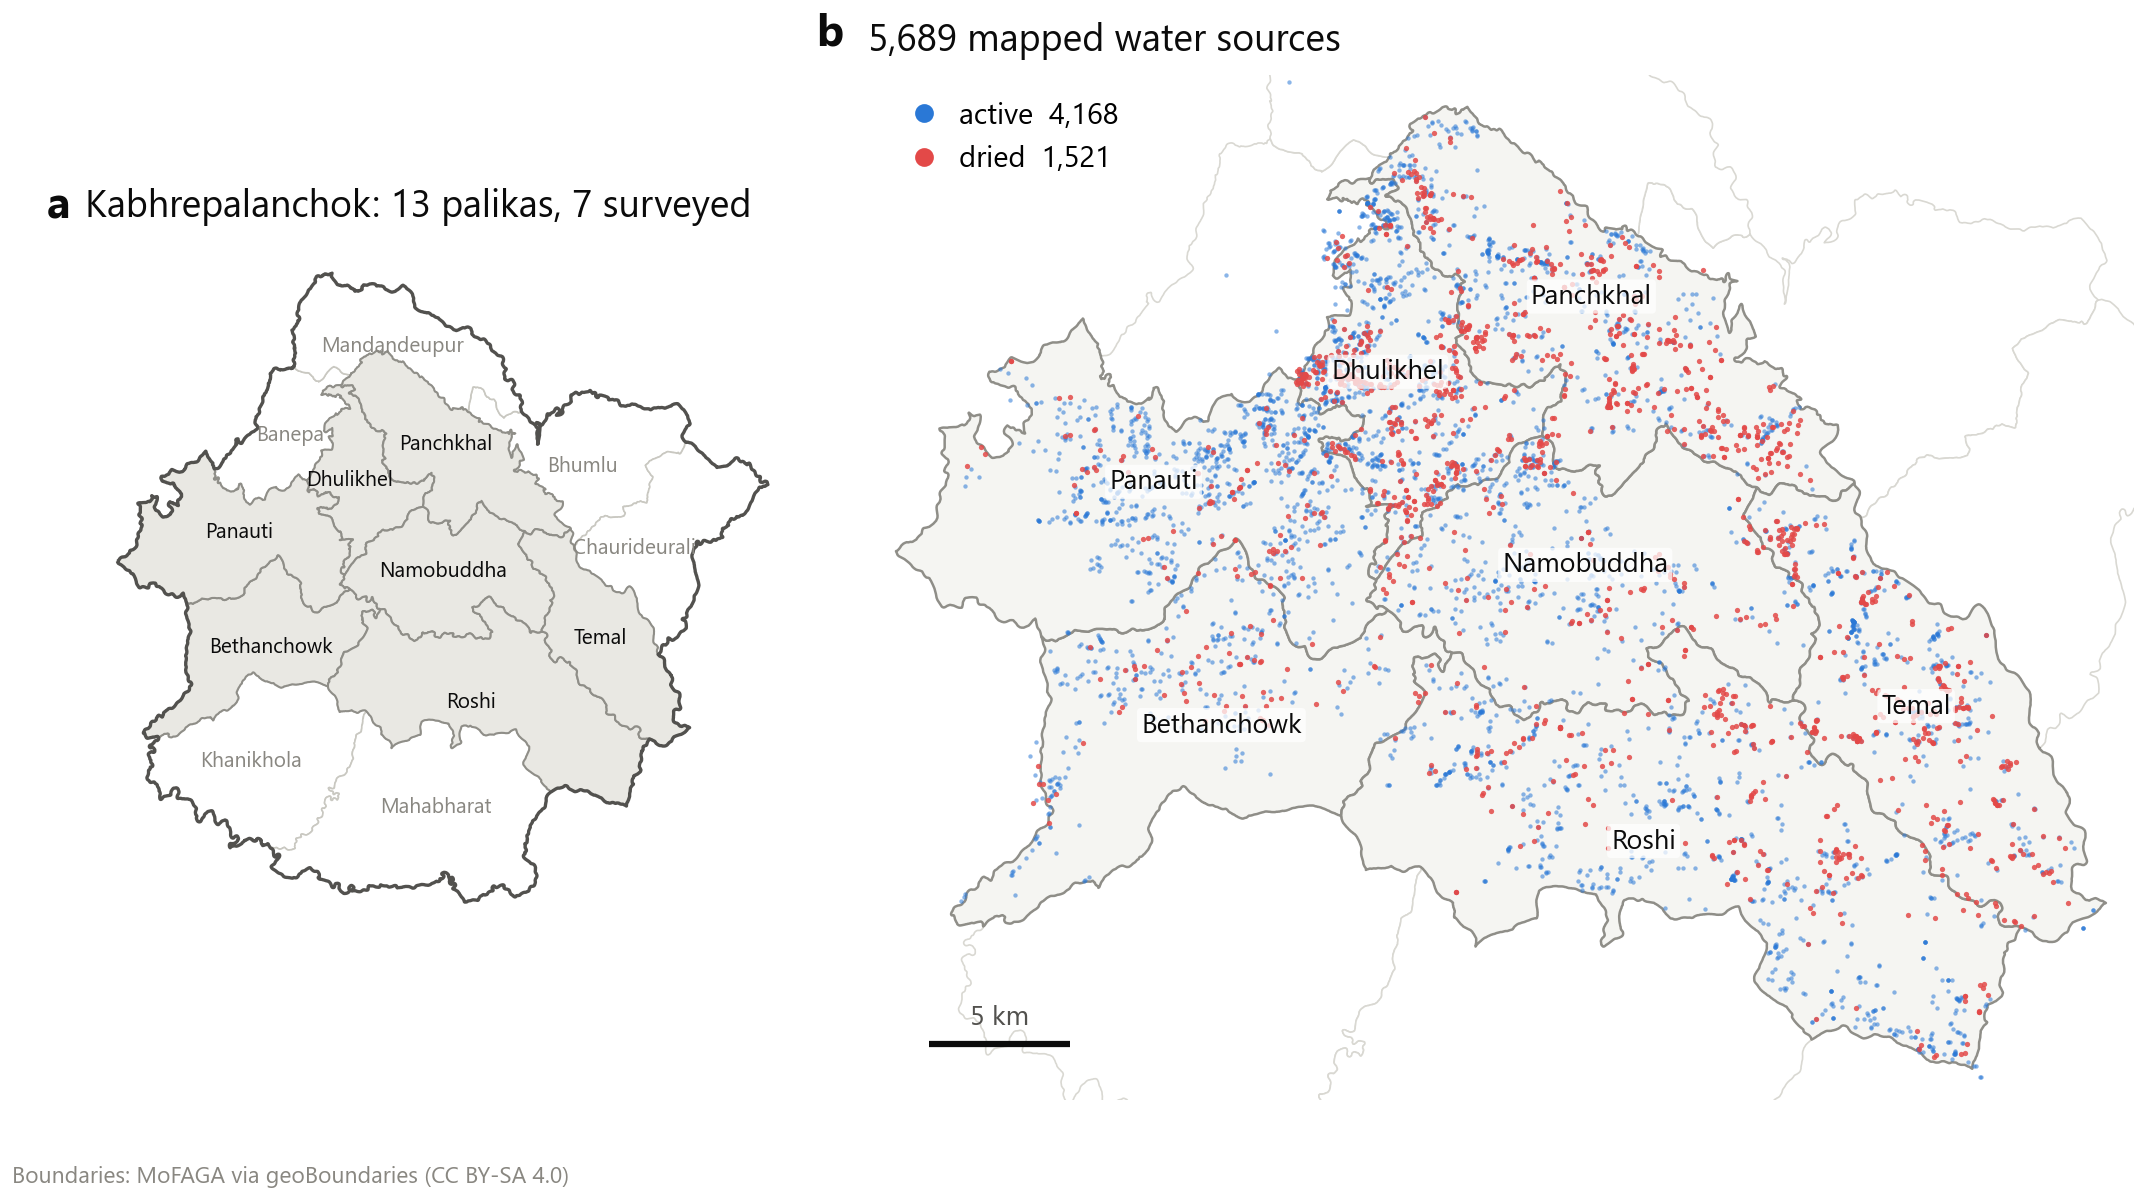

In [9]:
fig("fig1_study_area.png", 900)